# The U-Net Architecture

The U-Net Architecture was designed by Olaf R., Phillipp F. and Thomas B. in their seminal paper [U-Net: Convolutional Networks for Biomedical Image Segmentation](https://arxiv.org/abs/1505.04597) published in 2015.

As the title of the paper suggests, this architecture was specifically designed for Biomedical Image Segmentation. The architecture is detailed below.

In this notebook, I shall write the architecture of U-Net from scratch.

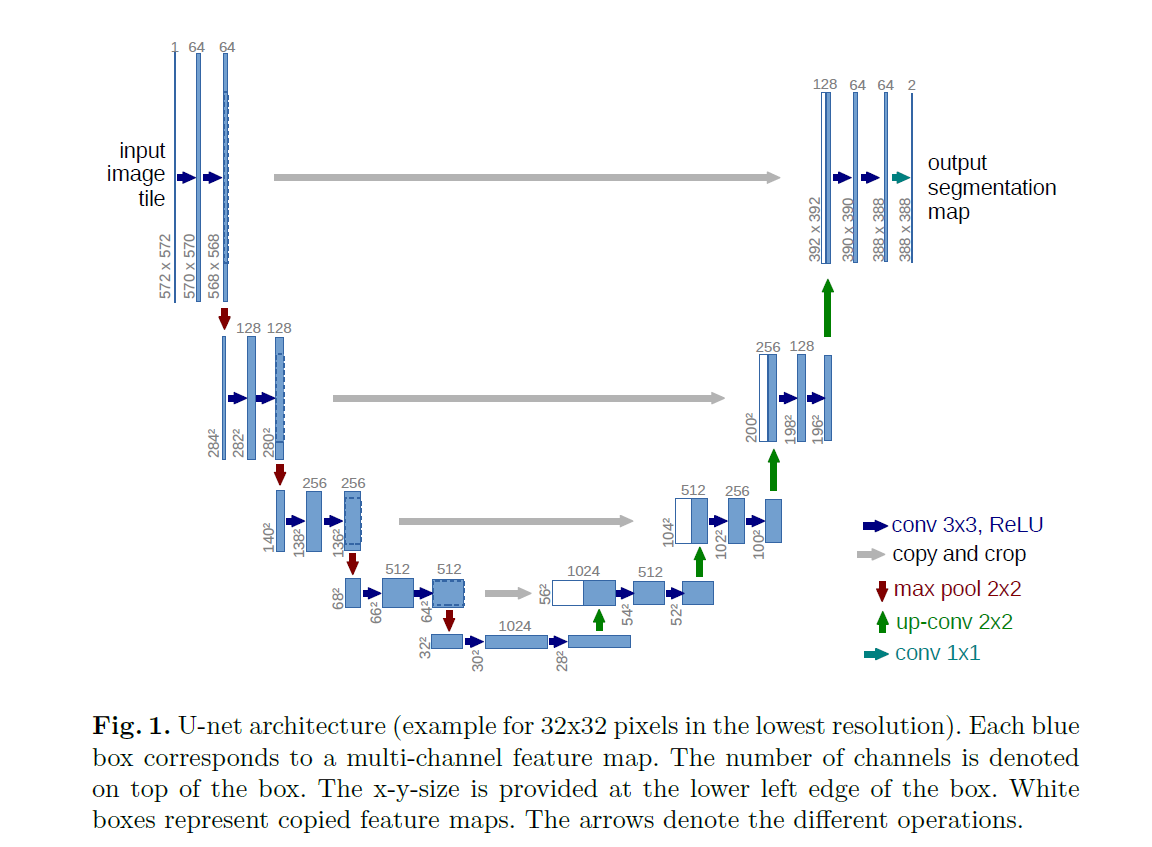


## The Model

In [2]:
import torch
import torch.nn as nn


In [3]:
class UNet(nn.Module):
    def __init__(self, in_channels=3, num_classes=1):
        super().__init__()

        # Encoder phase
        self.encoder1 = nn.Sequential(
            nn.Conv2d(in_channels, 64, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(64, 64, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
        )
        self.encoder2 = nn.Sequential(
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(128, 128, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
        )
        self.encoder3 = nn.Sequential(
            nn.Conv2d(128, 256, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(256, 256, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
        )
        self.encoder4 = nn.Sequential(
            nn.Conv2d(256, 512, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(512, 512, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
        )

        # Downsampling (shared, applied in forward)
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)

        # Transition phase (bottleneck)
        self.transition = nn.Sequential(
            nn.Conv2d(512, 1024, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(1024, 1024, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.ConvTranspose2d(1024, 512, kernel_size=2, stride=2),  # upsample
        )

        # Decoder phase
        self.decoder4 = nn.Sequential(
            nn.Conv2d(1024, 512, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(512, 512, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.ConvTranspose2d(512, 256, kernel_size=2, stride=2),
        )
        self.decoder3 = nn.Sequential(
            nn.Conv2d(512, 256, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(256, 256, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.ConvTranspose2d(256, 128, kernel_size=2, stride=2),
        )
        self.decoder2 = nn.Sequential(
            nn.Conv2d(256, 128, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(128, 128, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.ConvTranspose2d(128, 64, kernel_size=2, stride=2),
        )
        self.decoder1 = nn.Sequential(
            nn.Conv2d(128, 64, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(64, 64, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
        )

        # Output segmentation map
        self.out = nn.Conv2d(64, num_classes, kernel_size=1)

    def forward(self, x):
        e1 = self.encoder1(x)
        e2 = self.encoder2(self.pool(e1))
        e3 = self.encoder3(self.pool(e2))
        e4 = self.encoder4(self.pool(e3))

        x = self.transition(self.pool(e4))

        x = self.decoder4(torch.cat([x, e4], dim=1))
        x = self.decoder3(torch.cat([x, e3], dim=1))
        x = self.decoder2(torch.cat([x, e2], dim=1))
        x = self.decoder1(torch.cat([x, e1], dim=1))

        return self.out(x)

In [4]:
# dry run
UNet()(torch.randn(1, 3, 256, 256)).shape   # torch.Size([1, 2, 256, 256])

torch.Size([1, 1, 256, 256])

## The Application

### Data Loading

**Dataset Details**

The Kvasir dataset consists of images, annotated and verified by medical doctors (experienced endoscopists), including several classes showing anatomical landmarks, phatological findings or endoscopic procedures in the Gastro-Intestinal (GI) tract, i.e., hundreds of images for each class. The number of images is sufficient to be used for different tasks, e.g., image retrieval, machine learning, deep learning and transfer learning, etc. The anatomical landmarks include Z-line, pylorus, cecum, etc., while the pathological finding includes esophagitis, polyps, ulcerative colitis, etc. In addition, we provide several set of images related to removal of lesions, e.g., "dyed and lifted polyp", the "dyed resection margins", etc. The dataset consist of the images with different resolution from 720x576 up to 1920x1072 pixels and organized in a way where they are sorted in separate folders named accordingly to the content. Some of the included classes of images have a green picture in picture illustrating the position and configuration of the endoscope inside the bowel, by use of an electromagnetic imaging system (ScopeGuide, Olympus Europe) that may support the interpretation of the image. This type of information may be important for later investigations (thus included), but must be handled with care for the detection of the endoscopic findings.

In [5]:
import os, random, time
import numpy as np
from torch.utils.data import Dataset, DataLoader
from PIL import Image
import matplotlib.pyplot as plt

SEED = 5678
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = device.type == "cuda"
print(device, torch.cuda.get_device_name(0) if USE_AMP else "")

cuda Tesla T4


In [6]:
IMG_DIR = "/kaggle/input/datasets/impuneetmishra/kvasir-seg/images"
MASK_DIR = "/kaggle/input/datasets/impuneetmishra/kvasir-seg/masks"

names = sorted(os.listdir(IMG_DIR))
assert all(os.path.exists(os.path.join(MASK_DIR, n)) for n in names)
print(len(names), "image/mask pairs")

rng = random.Random(SEED)
rng.shuffle(names)
train_names, val_names, test_names = names[:800], names[800:900], names[900:]
print(len(train_names), len(val_names), len(test_names))

1000 image/mask pairs
800 100 100


In [7]:
IMG_SIZE = 256
MEAN = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
STD  = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

class KvasirSeg(Dataset):
    def __init__(self, names, augment=False):
        self.augment = augment
        self.images, self.masks = [], []
        for n in names:  # resize once and cache in RAM (~200 MB total)
            img = Image.open(os.path.join(IMG_DIR, n)).convert("RGB")
            img = img.resize((IMG_SIZE, IMG_SIZE), Image.BILINEAR)
            m = Image.open(os.path.join(MASK_DIR, n)).convert("L")
            m = m.resize((IMG_SIZE, IMG_SIZE), Image.NEAREST)
            self.images.append(np.array(img, dtype=np.uint8))
            self.masks.append((np.array(m) > 127).astype(np.uint8))  # JPEG masks -> strict 0/1

    def __len__(self):
        return len(self.images)

    def __getitem__(self, i):
        img = torch.from_numpy(self.images[i]).permute(2, 0, 1).float() / 255.0  # [3, H, W]
        mask = torch.from_numpy(self.masks[i]).unsqueeze(0).float()              # [1, H, W]

        if self.augment:  # identical transform on image and mask
            if random.random() < 0.5:
                img, mask = img.flip(-1), mask.flip(-1)
            if random.random() < 0.5:
                img, mask = img.flip(-2), mask.flip(-2)
            k = random.randint(0, 3)
            img = torch.rot90(img, k, dims=(1, 2))
            mask = torch.rot90(mask, k, dims=(1, 2))

        img = (img - MEAN) / STD
        return img, mask

torch.Size([8, 3, 256, 256]) torch.Size([8, 1, 256, 256]) tensor([0., 1.])


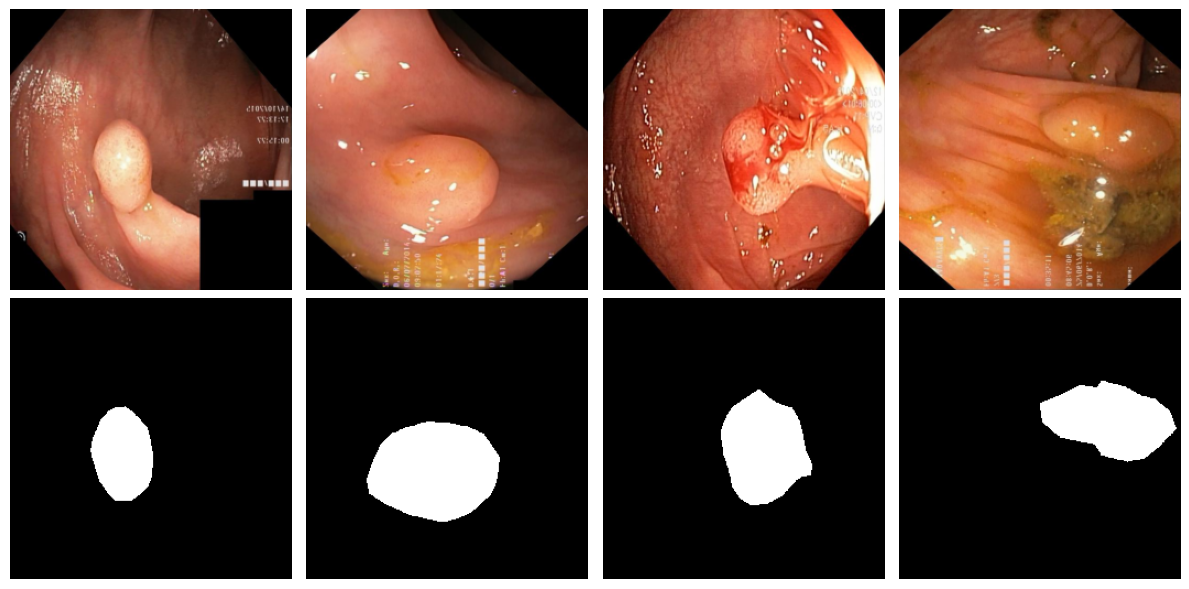

In [8]:
train_ds = KvasirSeg(train_names, augment=True)
val_ds   = KvasirSeg(val_names)
test_ds  = KvasirSeg(test_names)

BATCH = 8
train_dl = DataLoader(train_ds, batch_size=BATCH, shuffle=True,  num_workers=2, pin_memory=True, drop_last=True)
val_dl   = DataLoader(val_ds,   batch_size=BATCH, shuffle=False, num_workers=2, pin_memory=True)
test_dl  = DataLoader(test_ds,  batch_size=BATCH, shuffle=False, num_workers=2, pin_memory=True)

# sanity check
def denorm(img):
    return (img * STD + MEAN).clamp(0, 1).permute(1, 2, 0).numpy()

imgs, masks = next(iter(train_dl))
print(imgs.shape, masks.shape, masks.unique())  # expect [8,3,256,256], [8,1,256,256], tensor([0., 1.])

fig, ax = plt.subplots(2, 4, figsize=(12, 6))
for j in range(4):
    ax[0, j].imshow(denorm(imgs[j])); ax[0, j].axis("off")
    ax[1, j].imshow(masks[j, 0], cmap="gray"); ax[1, j].axis("off")
plt.tight_layout(); plt.show()

### Fetching Model

In [9]:
_m = UNet()
# model sanity check
print(_m(torch.randn(1,3,IMG_SIZE, IMG_SIZE)).shape)  # expect torch.Size([1, 1, 256, 256])
print(f"{sum(p.numel() for p in _m.parameters()) / 1e6:.1f} M parameters")

torch.Size([1, 1, 256, 256])
31.0 M parameters


<h3>The Loss: BCE-Dice</h3>

<h4>Dice coefficient</h4>

Dice measures the overlap between two sets: prediction $A$ and ground truth $B$.

$$D = \frac{2\,|A \cap B|}{|A| + |B|}$$

For a binary prediction $p_i \in \{0,1\}$ and ground truth $g_i \in \{0,1\}$ over $N$ pixels:

$$D = \frac{2\sum_i p_i g_i}{\sum_i p_i + \sum_i g_i} = \frac{2\,TP}{2\,TP + FP + FN}$$

It ranges from 0 (no overlap) to 1 (perfect overlap). It is identical to the F1 score, and it relates to IoU by $J = D / (2 - D)$.

<h4>Dice loss (soft Dice)</h4>

The thresholded version isn’t differentiable, so for training you replace $p_i$ with the sigmoid probabilities $p_i \in [0,1]$ and minimise:

$$\mathcal{L}_{\text{Dice}} = 1 - \frac{2\sum_i p_i g_i + s}{\sum_i p_i + \sum_i g_i + s}$$

$s$ is a smoothing constant (smooth=1.0 in your code). It prevents $0/0$ when both prediction and mask are empty, and stabilises training when the sums are small.

<h4>What BCE is?</h4>

Binary cross-entropy treats each pixel as an independent yes/no prediction. The model outputs $p_i \in (0,1)$, the probability that pixel $i$ is lesion. If you treat the ground truth $g_i \in \{0,1\}$ as a Bernoulli sample with that probability, its likelihood is:

$$P(g_i \mid p_i) = p_i^{\,g_i}(1-p_i)^{1-g_i}$$

Taking the negative log and averaging over all $N$ pixels gives BCE:

$$\mathcal{L}_{\text{BCE}} = -\frac{1}{N}\sum_{i=1}^{N}\Big[g_i \log p_i + (1-g_i)\log(1-p_i)\Big]$$

If the lesion covers 3% of the image, 97% of the BCE signal comes from background pixels. A model predicting “all background” already gets a low BCE and can get stuck there.

Dice contains only TP, FP and FN. True negatives don’t appear anywhere in the formula, so the background size is irrelevant. An all-background prediction gives $\sum p_i g_i = 0$, so Dice is 0 and the loss is 1, the worst possible score, no matter how small the lesion is. Dice is also the metric you report, so you’re optimising what you evaluate.

<h4>Why combine BCE with Dice?</h4>

Let $I = \sum p_i g_i$, $P = \sum p_i$ and $G = \sum g_i$. The gradient of Dice for pixel $j$ is:

$$\frac{\partial \mathcal{L}_{\text{Dice}}}{\partial p_j} = -\frac{2g_j(P + G) - 2I}{(P + G)^2}$$

Every pixel’s gradient depends on sums over the whole image, and the $(P+G)^2$ denominator makes gradients large and noisy when foreground sums are small. That happens early in training and on images with tiny lesions. BCE gives smooth, local per-pixel gradients. So the usual recipe is BCE for stable optimisation plus Dice for imbalance and direct metric alignment, which is what BCEDiceLoss does.

<h4>Summary</h4>

- **BCE** grades every pixel equally. With a tiny lesion, almost every pixel is background, so a model that says "no lesion anywhere" gets a good BCE score. It can get lazy and stuck there.
- **Dice** grades only overlap with the lesion. Background pixels don't count at all, so "no lesion anywhere" scores the worst possible. It forces the model to actually find the lesion.
- **But Dice alone is jumpy.** Its gradients depend on the whole image at once, so they're noisy, especially early in training or when the lesion is tiny.
- **BCE alone is stable.** Each pixel just gets nudged by its own error, so training is smooth.

**Together:** BCE keeps training stable, and Dice makes sure the model cares about the lesion rather than the background.

In [10]:
# defining loss and metrics
class BCEDiceLoss(nn.Module):
  def __init__(self, smooth=1.0):
    super().__init__()
    self.bce = nn.BCEWithLogitsLoss()
    self.smooth = smooth

  def forward(self, logits, target):
    logits = logits.float()
    bce = self.bce(logits, target)
    probs = torch.sigmoid(logits)
    inter = (probs * target).sum(dim=(1,2,3))   # intersection
    union = probs.sum(dim=(1,2,3)) + target.sum(dim=(1,2,3))
    dice = (2 * inter + self.smooth) / (union + self.smooth)
    return bce + (1 - dice.mean())


@torch.no_grad()
def dice_iou(logits, target, eps=1e-7):
    pred = (torch.sigmoid(logits.float()) > 0.5).float()
    inter = (pred * target).sum(dim=(1, 2, 3))
    p, t = pred.sum(dim=(1, 2, 3)), target.sum(dim=(1, 2, 3))
    dice = (2 * inter + eps) / (p + t + eps)
    iou = (inter + eps) / (p + t - inter + eps)
    return dice, iou  # shape [N], one value per image

### Training

In [11]:
def train_one_epoch(model, loader, optimizer, criterion, scaler):
    model.train()
    total, n = 0.0, 0
    for imgs, masks in loader:
        imgs, masks = imgs.to(device, non_blocking=True), masks.to(device, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=USE_AMP):
            logits = model(imgs)
            loss = criterion(logits, masks)
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        total += loss.item() * imgs.size(0)
        n += imgs.size(0)
    return total / n


@torch.no_grad()
def evaluate(model, loader, criterion):
    model.eval()
    total, n, dices, ious = 0.0, 0, [], []
    for imgs, masks in loader:
        imgs, masks = imgs.to(device, non_blocking=True), masks.to(device, non_blocking=True)
        with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=USE_AMP):
            logits = model(imgs)
            loss = criterion(logits, masks)
        total += loss.item() * imgs.size(0)
        n += imgs.size(0)
        d, i = dice_iou(logits, masks)
        dices.append(d.cpu()); ious.append(i.cpu())
    return total / n, torch.cat(dices).mean().item(), torch.cat(ious).mean().item()

In [12]:
model = UNet(in_channels=3, num_classes=1).to(device)
criterion = BCEDiceLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="max", factor=0.5, patience=5)
scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)

EPOCHS = 40
history = {"train_loss": [], "val_loss": [], "val_dice": [], "val_iou": []}
best_dice = 0.0

for epoch in range(1, EPOCHS + 1):
    t0 = time.time()
    tr_loss = train_one_epoch(model, train_dl, optimizer, criterion, scaler)
    va_loss, va_dice, va_iou = evaluate(model, val_dl, criterion)
    scheduler.step(va_dice)

    for k, v in zip(history, (tr_loss, va_loss, va_dice, va_iou)):
        history[k].append(v)

    flag = ""
    if va_dice > best_dice:
        best_dice = va_dice
        torch.save(model.state_dict(), "best_unet.pt")
        flag = "  *saved*"

    print(f"Epoch {epoch:02d} | train {tr_loss:.4f} | val {va_loss:.4f} | "
          f"Dice {va_dice:.4f} | IoU {va_iou:.4f} | {time.time() - t0:.0f}s{flag}")

Epoch 01 | train 1.2058 | val 1.1159 | Dice 0.0000 | IoU 0.0000 | 21s  *saved*
Epoch 02 | train 1.1316 | val 1.1077 | Dice 0.3224 | IoU 0.2206 | 19s  *saved*
Epoch 03 | train 1.1231 | val 1.0913 | Dice 0.3364 | IoU 0.2328 | 19s  *saved*
Epoch 04 | train 1.1087 | val 1.1200 | Dice 0.3751 | IoU 0.2633 | 20s  *saved*
Epoch 05 | train 1.1074 | val 1.0729 | Dice 0.2974 | IoU 0.2034 | 21s
Epoch 06 | train 1.1024 | val 1.0627 | Dice 0.3445 | IoU 0.2388 | 22s
Epoch 07 | train 1.0819 | val 1.0251 | Dice 0.4070 | IoU 0.2913 | 22s  *saved*
Epoch 08 | train 1.0162 | val 0.9514 | Dice 0.4405 | IoU 0.3179 | 21s  *saved*
Epoch 09 | train 1.0018 | val 0.9463 | Dice 0.4704 | IoU 0.3438 | 21s  *saved*
Epoch 10 | train 0.9974 | val 0.9640 | Dice 0.4194 | IoU 0.2988 | 21s
Epoch 11 | train 0.9923 | val 0.9429 | Dice 0.4416 | IoU 0.3204 | 21s
Epoch 12 | train 0.9825 | val 0.9535 | Dice 0.4164 | IoU 0.2979 | 21s
Epoch 13 | train 0.9834 | val 0.9567 | Dice 0.4674 | IoU 0.3419 | 21s
Epoch 14 | train 0.9761 | v

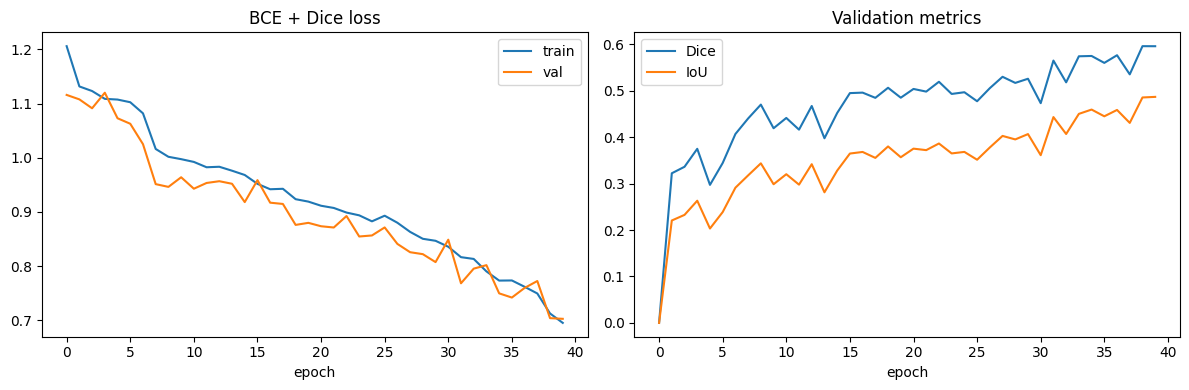

In [13]:
# training curves
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(history["train_loss"], label="train")
ax[0].plot(history["val_loss"], label="val")
ax[0].set_title("BCE + Dice loss"); ax[0].set_xlabel("epoch"); ax[0].legend()
ax[1].plot(history["val_dice"], label="Dice")
ax[1].plot(history["val_iou"], label="IoU")
ax[1].set_title("Validation metrics"); ax[1].set_xlabel("epoch"); ax[1].legend()
plt.tight_layout(); plt.show()

### Test

In [14]:
model.load_state_dict(torch.load("best_unet.pt"))
test_loss, test_dice, test_iou = evaluate(model, test_dl, criterion)
print(f"Test | Loss {test_loss:.4f} | Dice {test_dice:.4f} | IoU {test_iou:.4f}")

Test | Loss 0.6972 | Dice 0.6218 | IoU 0.5039


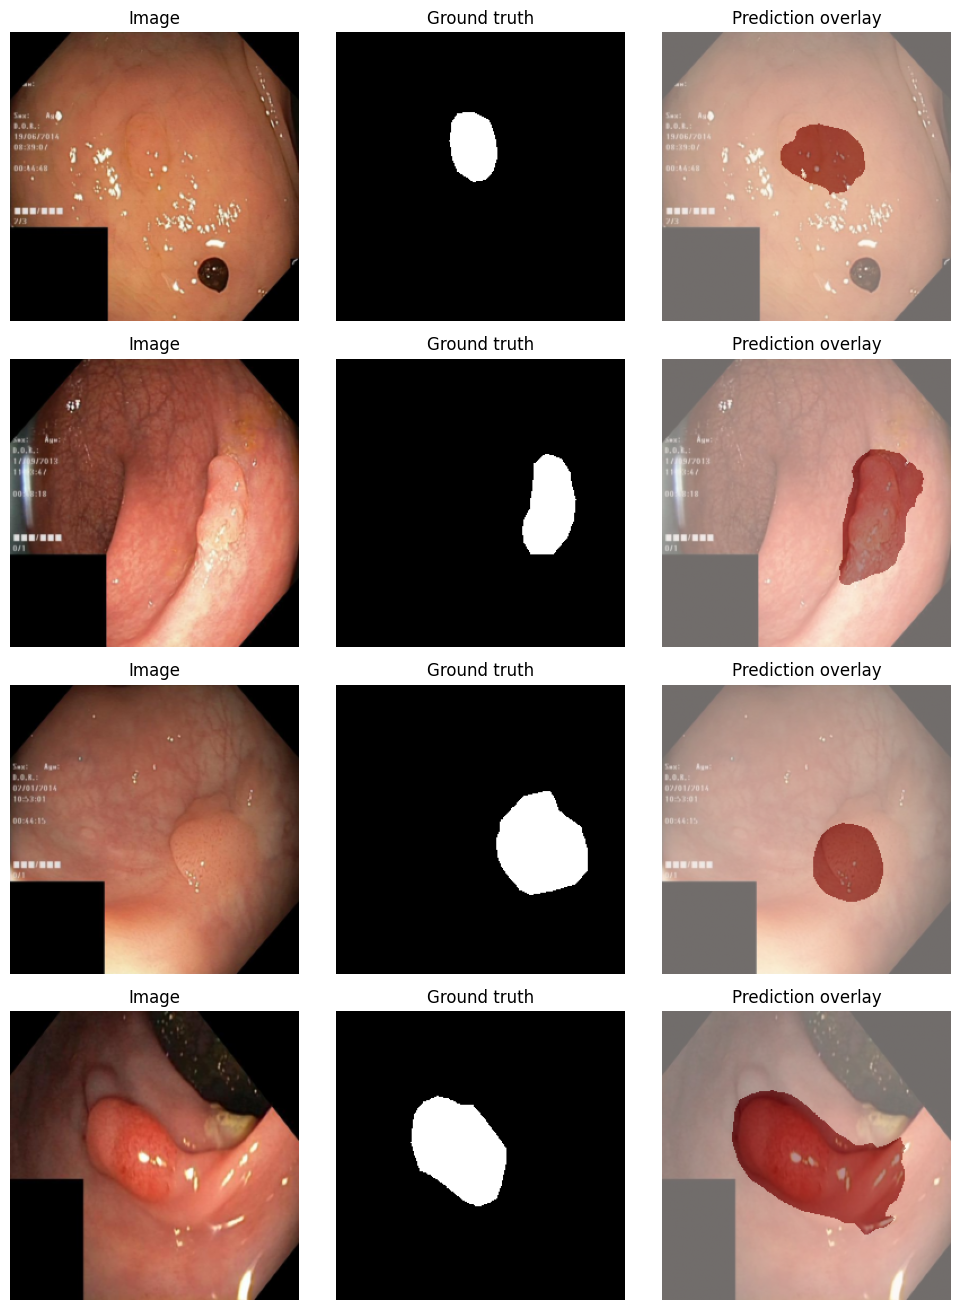

In [15]:
# visualize predictions
model.eval()
imgs, masks = next(iter(test_dl))
with torch.no_grad():
    preds = (torch.sigmoid(model(imgs.to(device)).float()) > 0.5).cpu()

n = 4
fig, ax = plt.subplots(n, 3, figsize=(10, 3.3 * n))
for j in range(n):
    ax[j, 0].imshow(denorm(imgs[j]));               ax[j, 0].set_title("Image")
    ax[j, 1].imshow(masks[j, 0], cmap="gray");      ax[j, 1].set_title("Ground truth")
    ax[j, 2].imshow(denorm(imgs[j]))
    ax[j, 2].imshow(preds[j, 0], cmap="Reds", alpha=0.45)
    ax[j, 2].set_title("Prediction overlay")
    for a in ax[j]: a.axis("off")
plt.tight_layout()
plt.savefig("sample_pred.png")
plt.show()